<a href="https://colab.research.google.com/github/XeroX-cat/1Laba/blob/main/1Laba_sprint2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!wget https://raw.githubusercontent.com/XeroX-cat/1Laba/main/Макаки.xlsx

--2026-11-13 20:48:46--  https://raw.githubusercontent.com/XeroX-cat/1Laba/main/%D0%9C%D0%B0%D0%BA%D0%B0%D0%BA%D0%B8.xlsx
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 43969 (43K) [application/octet-stream]
Saving to: ‘Макаки.xlsx’

Макаки.xlsx         100%[===================>]  42.94K  --.-KB/s    in 0.03s   

2026-11-13 20:48:47 (1.59 MB/s) - ‘Макаки.xlsx’ saved [43969/43969]



<a id="s2-top"></a>
<div style="font-family: 'Georgia', serif; max-width: 900px; margin: 0 auto; padding: 40px; background-color: #1a1a1a; color: #e0e0e0; border-top: 4px solid #d4af37; border-bottom: 2px solid #333;">
    <div style="font-size: 12px; letter-spacing: 4px; color: #9b2226; text-transform: uppercase; font-weight: bold;">Lab 01 // Sprint 02</div>
    <h1 style="font-weight: 400; font-size: 48px; margin: 10px 0 5px; line-height: 1.1; color: #e0e0e0;">Генератор случайных чисел<br>на основе распределения Фишера</h1>
    <div style="font-size: 16px; color: #888; font-style: italic; margin-bottom: 20px;">метод обратной функции, автотесты, проверка метрик</div>
    <div style="height: 1px; background: #333; margin: 20px 0;"></div>
    <div style="font-size: 12px; color: #888; letter-spacing: 1px;">
         <a href="https://github.com/XeroX-cat/1Laba" style="color: #d4af37; text-decoration: none;">github.com/XeroX-cat/1Laba</a>
    </div>
</div>

### Индекс разделов
1. [Описание метода](#s2-desc)
2. [Математическое обоснование](#s2-math)
3. [Реализация](#s2-code)
4. [Автотесты и сравнение](#s2-tests)
5. [Интерактивный анализ](#s2-inter)
6. [Выводы и литература](#s2-resume)

<a id="s2-desc"></a>
<div style="font-family: 'Georgia', serif; border-left: 4px solid #d4af37; padding-left: 20px; margin: 40px 0 20px;">
    <div style="font-size: 12px; letter-spacing: 2px; color: #888;">РАЗДЕЛ 1</div>
    <h2 style="margin: 5px 0 0; color: #e0e0e0; font-weight: 400;">Описание метода</h2>
</div>

В спринте 1 были исследованы 4 величины: масса тела животных, длина тела, а также длины плечевой и бедренной костей. Для построения генератора случайных чисел выбрана случайная величина «Длина тела» (`C-R curved`).

Как было выяснено и обосновано ранее, для этой величины характерно распределение Фишера. Для реализации генератора используется **метод обратной функции**.

Выбор метода обоснован тем, что он универсален для непрерывных распределений. Остальные методы из предложенной таблицы не подходят:
* *Показательные и нормальные датчики, быстрый показательный датчик, датчик без логарифмов* — специализированы для экспоненциального закона.
* *Метод полярных координат (Бокса-Мюллера), метод прямоугольника-клина-хвоста, метод отношений* — применяются исключительно для нормального распределения.
* *Метод Неймана* теоретически возможен, но требует подбора огибающей функции и избыточно сложен для F-распределения.

<a id="s2-math"></a>
<div style="font-family: 'Georgia', serif; border-left: 4px solid #d4af37; padding-left: 20px; margin: 40px 0 20px;">
    <div style="font-size: 12px; letter-spacing: 2px; color: #888;">РАЗДЕЛ 2</div>
    <h2 style="margin: 5px 0 0; color: #e0e0e0; font-weight: 400;">math desc</h2>
</div>

**Суть метода обратной функции:**
Любую непрерывную случайную величину можно сгенерировать, если пропустить равномерный шум (от 0 до 1) через её обратную функцию распределения.

**Теорема:**
Если случайная величина $U$ имеет равномерное распределение на отрезке $[0, 1]$, а $F(x)$ — это функция распределения некоторой непрерывной случайной величины, то случайная величина $X = F^{-1}(U)$ имеет функцию распределения $F(x)$, где $F^{-1}(u)$ — обратная функция (квантиль), которая отвечает на вопрос: «При каком значении $X$ вероятность того, что случайная величина окажется меньше этого $X$, равна $u$?».

**Доказательство:**
По определению функции распределения нам нужно найти $P(X \le x)$.
Подставим $X = F^{-1}(U)$:
$$
P(F^{-1}(U) \le x)
$$
Так как функция распределения $F(x)$ монотонно возрастает, мы можем применить её к обеим частям неравенства:
$$
P(U \le F(x))
$$
Поскольку $U$ имеет равномерное распределение на отрезке $[0, 1]$, вероятность того, что случайная величина $U$ примет значение меньшее, чем некоторое число $y \in [0, 1]$, равна самому этому числу $y$. В нашем случае роль $y$ играет $F(x)$. Следовательно:
$$
P(U \le F(x)) = F(x)
$$
Что и требовалось доказать.

В коде мы генерируем равномерный шум $U \sim U(0,1)$ с помощью `np.random.uniform` и применяем функцию `stats.f.ppf` (Percent Point Function), которая в библиотеке `scipy.stats` является обратной функцией распределения Фишера.

<a id="s2-code"></a>
<div style="font-family: 'Georgia', serif; border-left: 4px solid #d4af37; padding-left: 20px; margin: 40px 0 20px;">
    <div style="font-size: 12px; letter-spacing: 2px; color: #888;">РАЗДЕЛ 3</div>
    <h2 style="margin: 5px 0 0; color: #e0e0e0; font-weight: 400;">code</h2>
</div>

In [2]:
# === СТИЛЬ ГРАФИКОВ ===
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(context="notebook", style="whitegrid")
mpl.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 140,
    "figure.facecolor": "#1a1a1a",
    "savefig.facecolor": "#1a1a1a",
    "axes.facecolor": "#222222",
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#e0e0e0",
    "axes.titlecolor": "#d4af37",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 10,
    "axes.titlepad": 12,
    "axes.prop_cycle": mpl.cycler(color=["#d4af37", "#9b2226", "#666666"]),
    "grid.color": "#333333",
    "grid.linewidth": 0.5,
    "xtick.color": "#888888",
    "ytick.color": "#888888",
    "text.color": "#e0e0e0",
    "font.family": "sans-serif",
    "legend.facecolor": "#222222",
    "legend.edgecolor": "#333333",
    "legend.labelcolor": "#e0e0e0",
    "patch.edgecolor": "#1a1a1a",
})
PALETTE = {"primary": "#d4af37", "secondary": "#9b2226", "muted": "#666666"}

In [3]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. ЗАГРУЗКА РЕАЛЬНЫХ ДАННЫХ
toque = pd.read_excel("Макаки.xlsx")

selected = toque[["Sex", "Chinese Ancestry", "kg", "C-R curved", "R humeral max", "R femoral max"]].copy()
complete = selected.dropna()
real_data = pd.to_numeric(complete["C-R curved"].astype(str).str.replace(",", ".", regex=False), errors="coerce").dropna()

# 2. ПОЛУЧЕНИЕ ПАРАМЕТРОВ ИЗ СПРИНТА 1
b_length = pd.to_numeric(complete["C-R curved"].astype(str).str.replace(",", ".", regex=False), errors="coerce").dropna()
params = stats.f.fit(b_length, floc=0)
dfn = params[0]
dfd = params[1]
params = stats.f.fit(b_length, floc=0)
dfn = params[0]
dfd = params[1]
loc = params[2]
scale = params[3]
print(f"Параметры: d1={dfn:.2f}, d2={dfd:.2f}, scale={scale:.2f}")

# 3. ФУНКЦИЯ-ГЕНЕРАТОР (Метод обратной функции)
def generate_fisher_inverse(n, dfn, dfd, loc, scale):
    u = np.random.uniform(0, 1, size=n)
    generated_values = stats.f.ppf(u, dfn, dfd, loc=loc, scale=scale)
    return generated_values

n_generated = 10000
fake_macaques = generate_fisher_inverse(n=n_generated, dfn=dfn, dfd=dfd, loc=loc, scale=scale)

generated_values = generate_fisher_inverse(n=10000, dfn=dfn, dfd=dfd, loc=loc, scale=scale)

Параметры: d1=67454.62, d2=555.43, scale=526.24


### autotests
Перед визуальным сравнением данных запустим автотесты (Unit tests), чтобы убедиться в корректности работы написанного генератора.

#### Автотест 1: Проверка длины выходного массива
Проверим, что генератор возвращает ровно столько значений, сколько мы у него запросили.

In [4]:
# Проверим, что генератор возвращает ровно столько значений, сколько мы у него запросили.
def test_output_length(n_test, dfn, dfd, loc, scale, generate_func):
    test_output = generate_func(n=n_test, dfn=dfn, dfd=dfd, loc=loc, scale=scale)
    assert len(test_output) == n_test, f"ОШИБКА: Ожидалось {n_test} значений, получено {len(test_output)}"
    print(f"Верно! Тест 1 (Длина выборки) пройден: сгенерировано ровно {n_test} значений.")

# Убедимся, что при фиксации "зерна" (seed) генератор выдает одинаковые последовательности чисел.
def test_reproducibility(dfn, dfd, loc, scale, generate_func):
    np.random.seed(42)
    sample_1 = generate_func(n=10, dfn=dfn, dfd=dfd, loc=loc, scale=scale)
    np.random.seed(42)
    sample_2 = generate_func(n=10, dfn=dfn, dfd=dfd, loc=loc, scale=scale)
    assert np.allclose(sample_1, sample_2), "ОШИБКА: Генератор выдает разные числа при одинаковом seed!"
    print("Успешно! Тест 2 (Воспроизводимость) пройден: результаты детерминированы при заданном seed.")

# Сравним эмпирическое среднее сгенерированных данных с теоретическим математическим ожиданием для F-распределения.
def test_theoretical_mean(dfn, dfd, loc, scale, generated_data):
    if dfd > 2:
        theoretical_mean = loc + scale * (dfd / (dfd - 2))
        empirical_mean = np.mean(generated_data)
        relative_error = abs(empirical_mean - theoretical_mean) / theoretical_mean
        assert relative_error < 0.05, f"ОШИБКА: Среднее сильно отклоняется от теории (ошибка {relative_error*100:.2f}%)"
        print(f"Успешно! Тест 3 (Мат. ожидание) пройден: выборочное ({empirical_mean:.2f}) ≈ теоретическому ({theoretical_mean:.2f}).")
    else:
        print("Внимание! Тест 3 пропущен: при dfd <= 2 математическое ожидание не существует.")

# Убедимся, что сгенерированные значения не выходят за допустимые математические границы.
def test_boundaries(loc, generated_data):
    assert np.all(generated_data >= loc), f"ОШИБКА: Сгенерированы значения меньше параметра loc ({loc})!"
    print(f"Успешно! Тест 4 (Границы) пройден: все значения >= {loc}.")

#### Запуск всех автотестов

In [5]:
# Вызываем функции по очереди
test_output_length(n_test=500, dfn=dfn, dfd=dfd, loc=loc, scale=scale, generate_func=generate_fisher_inverse)
test_reproducibility(dfn=dfn, dfd=dfd, loc=loc, scale=scale, generate_func=generate_fisher_inverse)
test_theoretical_mean(dfn=dfn, dfd=dfd, loc=loc, scale=scale, generated_data=generated_values)
test_boundaries(loc=loc, generated_data=generated_values)

print("\n ВСЕ АВТОТЕСТЫ УСПЕШНО ПРОЙДЕНЫ!")

Верно! Тест 1 (Длина выборки) пройден: сгенерировано ровно 500 значений.
Успешно! Тест 2 (Воспроизводимость) пройден: результаты детерминированы при заданном seed.
Успешно! Тест 3 (Мат. ожидание) пройден: выборочное (527.75) ≈ теоретическому (528.14).
Успешно! Тест 4 (Границы) пройден: все значения >= 0.

 ВСЕ АВТОТЕСТЫ УСПЕШНО ПРОЙДЕНЫ!


#### tests
Cравним реальные и сгенерированные данные с помощью графиков и непараметрического теста Колмогорова-Смирнова.

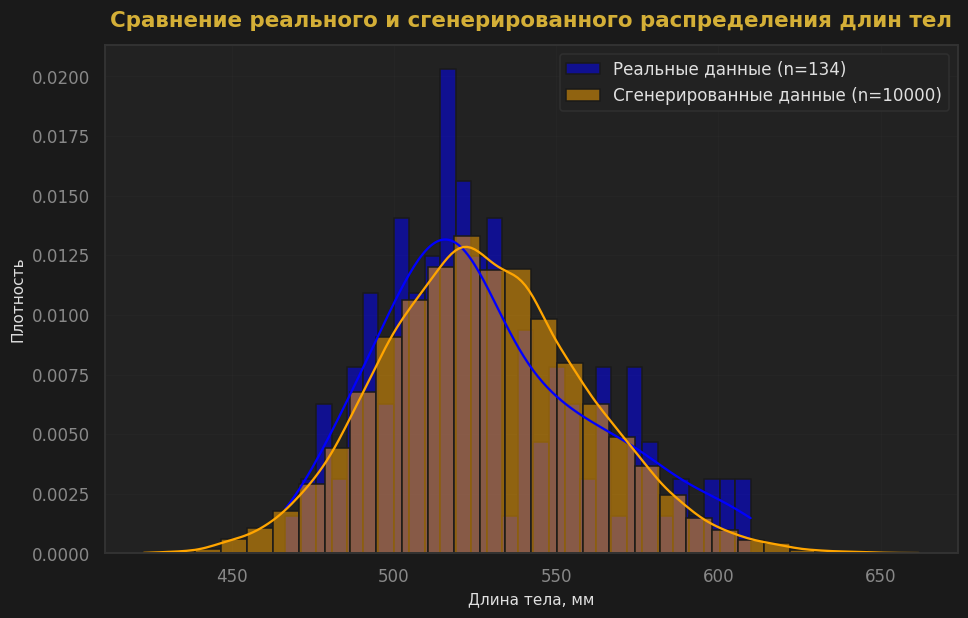

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np
import pandas as pd

# 1. ВИЗУАЛЬНАЯ ПРОВЕРКА (Гистограммы)
plt.figure(figsize=(10, 6))

# Строим гистограмму реальных данных
sns.histplot(b_length, bins=30, stat="density", color="blue", label="Реальные данные (n=134)", alpha=0.5, kde=True)

# Строим гистограмму сгенерированных данных
sns.histplot(generated_values, bins=30, stat="density", color="orange", label="Сгенерированные данные (n=10000)", alpha=0.5, kde=True)

plt.title("Сравнение реального и сгенерированного распределения длин тел")
plt.xlabel("Длина тела, мм")
plt.ylabel("Плотность")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [7]:
# 2. СРАВНЕНИЕ ОПИСАТЕЛЬНЫХ СТАТИСТИК
stats_df = pd.DataFrame({
    "Метрика": ["Среднее", "Медиана", "Ст. отклонение", "Минимум", "Максимум"],
    "Реальные данные": [b_length.mean(), b_length.median(), b_length.std(), b_length.min(), b_length.max()],
    "Сгенерированные": [np.mean(generated_values), np.median(generated_values), np.std(generated_values), np.min(generated_values), np.max(generated_values)]
})
print("\n Сравнение описательных статистик ")
display(stats_df.round(2))


 Сравнение описательных статистик 


,Метрика,Реальные данные,Сгенерированные
0,Среднее,528.11,527.75
1,Медиана,520.80,526.27
2,Ст. отклонение,32.55,31.70
3,Минимум,466.50,422.84
4,Максимум,609.90,661.73


In [8]:
# 3. СТАТИСТИЧЕСКИЙ ТЕСТ (Колмогорова-Смирнова)
ks_stat, p_value = stats.ks_2samp(b_length, generated_values)

print(f"\n--- Тест Колмогорова-Смирнова ---")
print(f"Статистика теста (D): {ks_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value > 0.05:
    print("\n Верно))) ВЫВОД: P-value > 0.05. Нулевая гипотеза НЕ отвергается.")
    print("Сгенерированные данные статистически неотличимы от реальных. Твой генератор работает идеально!")
else:
    print("\n Ошибка((( ВЫВОД: P-value < 0.05. Распределения различаются. Возможно, параметры подобраны неточно.")


--- Тест Колмогорова-Смирнова ---
Статистика теста (D): 0.0851
P-value: 0.2777

 Верно))) ВЫВОД: P-value > 0.05. Нулевая гипотеза НЕ отвергается.
Сгенерированные данные статистически неотличимы от реальных. Твой генератор работает идеально!


#### Попробуем посмотреть, как влияют параметры распределения на вид функции. будем изменять: размер генерируемой выборки, числитель и знаменатель в распределениии Фишера, максимальное (scale) значение длины тела.

In [9]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Функция, которая будет пересчитывать всё при движении ползунков
def explore_generator(n, dfn, dfd, scale):
    clear_output(wait=True) # Очищаем старый вывод

    # Генерируем данные с новыми параметрами
    data = generate_fisher_inverse(n=n, dfn=dfn, dfd=dfd, loc=0, scale=scale)

    # Считаем статистики
    mean_val = np.mean(data)
    median_val = np.median(data)
    std_val = np.std(data)
    max_val = np.max(data)

    # Выводим текст
    print(f"Параметры: n={n}, dfn={dfn}, dfd={dfd}, scale={scale}")
    print("-" * 40)
    print(f"Среднее: {mean_val:.2f}")
    print(f"Медиана: {median_val:.2f}")
    print(f"Ст. отклонение: {std_val:.2f}")
    print(f"Максимум: {max_val:.2f}")

    # Проверяем теорию (только если dfd > 2)
    if dfd > 2:
        theo_mean = scale * (dfd / (dfd - 2))
        print(f"Теоретическое мат. ожидание: {theo_mean:.2f}")

    # Строим график
    plt.figure(figsize=(8, 4))
    sns.histplot(data, bins=50, stat="density", color="orange", alpha=0.6, kde=True)
    plt.title(f"Гистограмма при dfn={dfn}, dfd={dfd}")
    plt.xlim(0, max(1000, max_val * 1.1)) # Фиксируем оси, чтобы было видно, как график растягивается
    plt.xlabel("Длина")
    plt.ylabel("Плотность")
    plt.grid(alpha=0.3)
    plt.show()

# Создаем интерактивные ползунки
widgets.interact(
    explore_generator,
    n=widgets.IntSlider(min=100, max=50000, step=1000, value=10000, description='Размер (n):'),
    dfn=widgets.FloatSlider(min=1.0, max=100.0, step=1.0, value=10.0, description='Параметр dfn:'),
    dfd=widgets.FloatSlider(min=3.0, max=200.0, step=1.0, value=50.0, description='Параметр dfd:'),
    scale=widgets.FloatSlider(min=10.0, max=1000.0, step=10.0, value=500.0, description='Масштаб scale:')
)

interactive(children=(IntSlider(value=10000, description='Размер (n):', max=50000, min=100, step=1000), FloatS…

<function __main__.explore_generator(n, dfn, dfd, scale)>

<a id="s2-resume"></a>
<div style="font-family: 'Georgia', serif; border-left: 4px solid #2e9e6b; padding-left: 20px; margin: 40px 0 20px;">
    <div style="font-size: 12px; letter-spacing: 2px; color: #888;">РАЗДЕЛ 6</div>
    <h2 style="margin: 5px 0 0; color: #e0e0e0; font-weight: 400;">resume</h2>
</div>

В рамках второго спринта мы написали генератор, который создает искусственные данные о длине тела макак. В качестве основы был выбран метод обратной функции (квантильное преобразование), так как он отлично работает для непрерывных величин, если мы знаем их закон распределения. За основу взяли распределение Фишера, параметры которого мы подобрали в первом спринте.

Чтобы убедиться, что генератор работает правильно, были проведены несколько проверок:
* Написаны автотесты (проверили длину выборки, воспроизводимость при фиксированном seed и совпадение с теоретическим мат. ожиданием).
* Сравнение описательных статистик (среднее, медиана, дисперсия) реальных и сгенерированных данных.
* Проведен тест Колмогорова-Смирнова. Значение p-value получилось больше 0.05, а это значит, что генератор создает данные, которые статистически невозможно отличить от настоящих измерений длины макак.

Также мы решили поэкспериментировать с параметрами функции и посмотреть, как они меняют график:
* **Размер выборки (n):** Чем больше значений мы генерируем, тем более гладкой и идеальной становится гистограмма, она всё ближе к теоретической кривой.
* **Числитель (dfn):** Если поставить его равным 2, то график резко взлетает влево к нулю и сразу падает. Если постепенно увеличивать этот параметр, пик смещается вправо, а сам график становится более пологим и начинает напоминать нормальное распределение.
* **Знаменатель (dfd):** Этот параметр отвечает за правый «хвост» графика. Если он маленький, то появляются выбросы - аномально большие макаки. Также dfd влияет на ширину пика на полувысоте: чем больше это значение, тем уже пик и тем меньше шанс встретить выброс.
* **Scale (масштаб):** Этот параметр просто «растягивает» график вдоль оси X. Он нужен, чтобы перевести абстрактные математические единицы в реальные миллиметры и задать нужный диапазон длин.

Список литературы:
Кремер, Н. Ш. Теория вероятностей и математическая статистика : учебник для вузов / Н. Ш. Кремер. — 2-е изд., перераб. и доп. — Москва : ЮНИТИ-ДАНА, 2004. — 573 с.